<a href="https://colab.research.google.com/github/Dharshanyaselva/titanic_data_visualization/blob/main/Titaic_EDA_Project_ipy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- First 5 Rows ---
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

--- Missing Values Before Cleaning ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class 

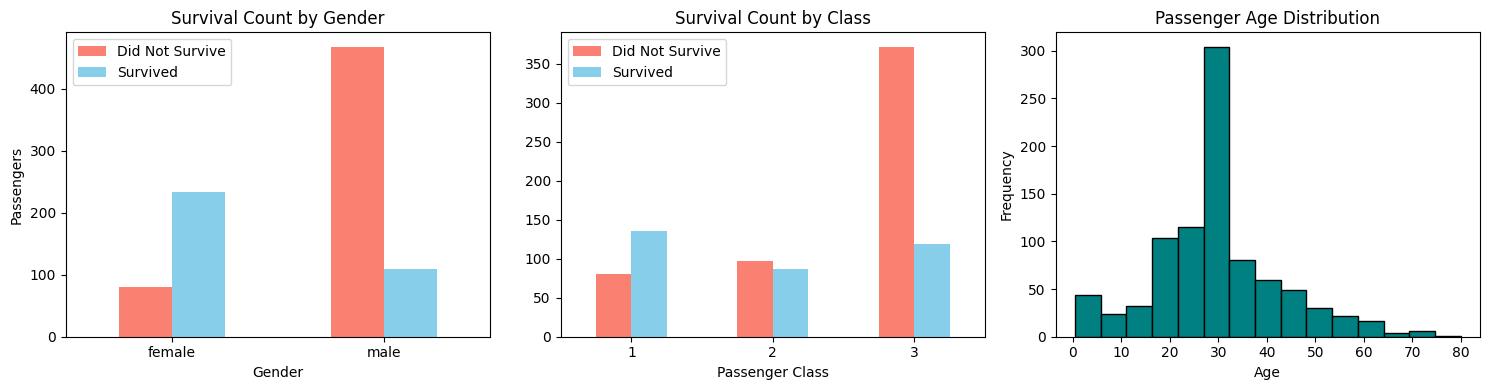

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load Full Built-in Titanic Dataset (No internet URL needed!)
df = sns.load_dataset("titanic")

print("--- First 5 Rows ---")
print(df.head())

print("\n--- Missing Values Before Cleaning ---")
print(df.isnull().sum())

# 2. Data Cleaning
df["age"] = df["age"].fillna(df["age"].median())
df = df.drop(columns=["deck"])  # 'deck' is the cabin deck column in seaborn's version

print("\n--- Survival Rate by Gender ---")
print(df.groupby("sex")["survived"].mean())

print("\n--- Survival Rate by Passenger Class ---")
print(df.groupby("pclass")["survived"].mean())

# 3. Visualizations
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Chart 1: Survival by Gender
df.groupby(["sex", "survived"]).size().unstack().plot(kind="bar", color=["salmon", "skyblue"], ax=axes[0])
axes[0].set_title("Survival Count by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Passengers")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(["Did Not Survive", "Survived"])

# Chart 2: Survival by Passenger Class
df.groupby(["pclass", "survived"]).size().unstack().plot(kind="bar", color=["salmon", "skyblue"], ax=axes[1])
axes[1].set_title("Survival Count by Class")
axes[1].set_xlabel("Passenger Class")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["Did Not Survive", "Survived"])

# Chart 3: Age Distribution
df["age"].plot(kind="hist", bins=15, color="teal", edgecolor="black", ax=axes[2])
axes[2].set_title("Passenger Age Distribution")
axes[2].set_xlabel("Age")

plt.tight_layout()
plt.show()

### Summary of Three Key Findings

1. **Gender Strongly Influenced Survival:** Female passengers had a significantly higher survival rate (approx. 74.2%) compared to male passengers (approx. 18.9%), reflecting the "women and children first" evacuation priority.
2. **Passenger Class (`pclass`) Impacted Survival:** First-class passengers had the highest survival rate (approx. 63.0%), followed by second-class (approx. 47.3%), while third-class passengers had the lowest (approx. 24.2%).
3. **Missing Values & Age Distribution:** The dataset had substantial missing values in `deck` (688 missing) and `age` (177 missing), which were handled by dropping `deck` and imputing `age` with the median. Most passengers aboard were young adults aged between 20 and 40.
4.